
# Atlas pair spread analysis

This notebook diagnoses every fixed atlas pair used by `teamName.py`.

It deliberately separates two kinds of information:

- **Causal strategy diagnostics** reproduce the atlas calculation at each historical decision point using only information available at that point.
- **Descriptive full-sample statistics** (OLS, Engle–Granger and full-history stability) describe the supplied dataset but are not runtime signals and must not be read as OOS proof.

The atlas implementation fits an expanding Kalman intercept/slope through the close before the decision close, then forms

\[
s_t = \log P_{i,t} - \hat\beta_{t-1}\log P_{j,t}.
\]

It trades equal-dollar legs—not beta-weighted legs—when all three gates pass:

1. ADF(1) spread statistic `< -2.9`;
2. 120-day OU kappa `> 0`;
3. `0.27 <= abs(z_145) <= 4`.

Positive z means the first asset is rich relative to the second, so the atlas shorts the first and buys the second. Figures and CSV tables are also written to `cointegration_output/atlas_pair_spreads/`.


In [10]:

from pathlib import Path
import types
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.tsa.stattools import coint

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 220)

ROOT = Path.cwd()
OUT_DIR = ROOT / "cointegration_output" / "atlas_pair_spreads"
OUT_DIR.mkdir(parents=True, exist_ok=True)

prices_df = pd.read_csv(ROOT / "prices.txt", sep=r"\s+")
names = prices_df.columns.to_list()
prices = prices_df.to_numpy(float).T
log_prices = np.log(prices)
n_inst, n_days = prices.shape

# Load source directly so a stale .pyc cannot change the analysis.
strategy_path = ROOT / "teamName.py"
strategy = types.ModuleType("teamName_source")
strategy.__file__ = str(strategy_path)
exec(compile(strategy_path.read_text(encoding="utf-8"), str(strategy_path), "exec"), strategy.__dict__)

atlas_pairs = list(strategy.ATLAS_PAIRS)
assert len(atlas_pairs) == 13
print(f"Loaded {n_inst} assets, {n_days} closes, and {len(atlas_pairs)} atlas pairs.")
print("Atlas:", ", ".join(f"{names[i]}~{names[j]}" for i, j in atlas_pairs))


Loaded 51 assets, 750 closes, and 13 atlas pairs.
Atlas: SMAH~ILVX, AENO~NWIG, EORC~NGTE, HUXZ~ACAC, CTGI~EELT, MHRM~EAFC, HETT~ULXY, ACIX~ITPA, FWWG~BLBT, RTTH~NAYO, MTNS~ALUT, NAYO~SRTX, ALUT~CCNS



## Exact causal reconstruction and statistical helpers

`atlas_snapshot` mirrors `_atlas_dollars` for one pair. The current close is excluded from the Kalman beta fit, but is included in the spread and gate calculations, matching the submission code exactly.

The standalone PnL attribution below applies each pair in isolation with integer shares and 1 bp turnover costs. It is intentionally labelled standalone: atlas pairs share some instruments, and the complete strategy later clips combined instrument exposure.


In [11]:

LEG = float(strategy.LEG)
ADF_GATE = -2.9
Z_DEAD = 0.27
Z_MAX = 4.0
Z_WINDOW = 145
KAPPA_WINDOW = 120


def ols_fit(y, x):
    xc = x - x.mean()
    yc = y - y.mean()
    beta = float(xc @ yc / max(xc @ xc, 1e-18))
    alpha = float(y.mean() - beta * x.mean())
    residual = y - alpha - beta * x
    ss_res = float(residual @ residual)
    ss_tot = float(yc @ yc)
    r2 = 1.0 - ss_res / max(ss_tot, 1e-18)
    return alpha, beta, residual, r2


def ar1_diagnostics(series):
    lag = series[:-1] - series[:-1].mean()
    lead = series[1:] - series[1:].mean()
    phi = float(lag @ lead / max(lag @ lag, 1e-18))
    half_life = float(-np.log(2.0) / np.log(phi)) if 0.0 < phi < 1.0 else np.inf
    return phi, half_life


def max_drawdown(pnl):
    cumulative = np.cumsum(np.asarray(pnl, float))
    if not len(cumulative):
        return 0.0
    wealth = np.r_[0.0, cumulative]
    return float(np.min(wealth - np.maximum.accumulate(wealth)))


def atlas_snapshot(i, j, end):
    '''Exact pair state using closes [0, end), with close end-1 current.'''
    if end < 130:
        return None
    beta = strategy._kalman_beta(log_prices[i, :end - 1], log_prices[j, :end - 1])
    spread = log_prices[i, :end] - beta * log_prices[j, :end]
    adf_t = float(strategy._adf1_tstats(spread.reshape(-1, 1))[0])
    recent = spread[-Z_WINDOW:]
    z = float((recent[-1] - recent[:-1].mean()) / (recent[:-1].std() + 1e-12))
    kappa = float(strategy._ou_kappa(spread[-KAPPA_WINDOW:]))
    adf_pass = adf_t < ADF_GATE
    kappa_pass = kappa > 0.0
    z_pass = Z_DEAD <= abs(z) <= Z_MAX
    active = bool(adf_pass and kappa_pass and z_pass)
    direction = float(-np.sign(z)) if active else 0.0
    return {
        "beta": beta,
        "spread": spread,
        "adf_t": adf_t,
        "kappa": kappa,
        "z": z,
        "adf_pass": adf_pass,
        "kappa_pass": kappa_pass,
        "z_pass": z_pass,
        "active": active,
        "direction": direction,
    }


def causal_history(i, j, first_day=129, last_day=None):
    '''One row per zero-based decision close, always using prior information.'''
    if last_day is None:
        last_day = n_days - 1
    rows = []
    for day in range(first_day, last_day + 1):
        state = atlas_snapshot(i, j, day + 1)
        rows.append({"day": day, **{k: v for k, v in state.items() if k != "spread"}})
    return pd.DataFrame(rows)


def standalone_attribution(i, j, history, start_day=249, end_day=748):
    '''Daily next-close standalone pair PnL with integer shares and 1 bp costs.'''
    by_day = history.set_index("day")
    previous = np.zeros(2, dtype=int)
    pnl, held_pnl, active_flags = [], [], []
    turnover = 0.0
    entries = 0
    previous_direction = 0.0
    for day in range(start_day, end_day + 1):
        row = by_day.loc[day]
        direction = float(row.direction)
        target = np.zeros(2, dtype=int)
        if direction:
            target[0] = int(direction * LEG / prices[i, day])
            target[1] = int(-direction * LEG / prices[j, day])
        delta = target - previous
        day_turnover = float(
            prices[i, day] * abs(delta[0]) + prices[j, day] * abs(delta[1])
        )
        day_pnl = float(
            target[0] * (prices[i, day + 1] - prices[i, day])
            + target[1] * (prices[j, day + 1] - prices[j, day])
            - 0.0001 * day_turnover
        )
        if direction and direction != previous_direction:
            entries += 1
        pnl.append(day_pnl)
        if direction:
            held_pnl.append(day_pnl)
        active_flags.append(bool(direction))
        turnover += day_turnover
        previous = target
        previous_direction = direction

    pnl = np.asarray(pnl)
    held_pnl = np.asarray(held_pnl)
    sigma = pnl.std()
    return {
        "eval_days": len(pnl),
        "active_days": int(np.sum(active_flags)),
        "active_pct": float(np.mean(active_flags) * 100.0),
        "entries": entries,
        "net_pnl": float(pnl.sum()),
        "mean_daily_pnl": float(pnl.mean()),
        "annual_sharpe": float(np.sqrt(250.0) * pnl.mean() / sigma) if sigma > 0 else np.nan,
        "active_day_hit_rate": float(np.mean(held_pnl > 0)) if len(held_pnl) else np.nan,
        "max_drawdown": max_drawdown(pnl),
        "turnover": turnover,
    }


In [12]:

causal = {}
relationship_rows = []
trading_rows = []

market_returns = np.diff(log_prices[1:], axis=1).mean(axis=0)

for pair_number, (i, j) in enumerate(atlas_pairs, start=1):
    label = f"{names[i]}~{names[j]}"
    history = causal_history(i, j, last_day=n_days - 1)
    causal[label] = history
    current = atlas_snapshot(i, j, n_days)

    y, x = log_prices[i], log_prices[j]
    alpha, ols_beta, ols_residual, r2 = ols_fit(y, x)
    _, beta_first, _, _ = ols_fit(y[:n_days // 2], x[:n_days // 2])
    _, beta_second, _, _ = ols_fit(y[n_days // 2:], x[n_days // 2:])
    beta_change = 100.0 * (beta_second - beta_first) / max(abs(beta_first), 1e-12)

    fixed_spread = y - current["beta"] * x
    phi, half_life = ar1_diagnostics(fixed_spread)
    return_corr = float(np.corrcoef(np.diff(y), np.diff(x))[0, 1])
    spread_return = np.diff(y) - current["beta"] * np.diff(x)
    residual_market_beta = float(
        np.cov(spread_return, market_returns, ddof=0)[0, 1]
        / max(np.var(market_returns), 1e-18)
    )
    try:
        eg_forward = float(coint(y, x, maxlag=1, autolag=None)[1])
        eg_reverse = float(coint(x, y, maxlag=1, autolag=None)[1])
    except Exception:
        eg_forward = eg_reverse = np.nan

    if current["active"]:
        signal = (
            f"Long {names[i]} / Short {names[j]}"
            if current["direction"] > 0
            else f"Short {names[i]} / Long {names[j]}"
        )
    else:
        signal = "Flat"

    current_i_shares = int(current["direction"] * LEG / prices[i, -1])
    current_j_shares = int(-current["direction"] * LEG / prices[j, -1])

    relationship_rows.append({
        "pair": label,
        "i": i,
        "j": j,
        "current_kalman_beta": current["beta"],
        "full_OLS_alpha": alpha,
        "full_OLS_beta": ols_beta,
        "full_OLS_R2": r2,
        "half_beta_change_pct": beta_change,
        "return_correlation": return_corr,
        "EG_p_i_on_j": eg_forward,
        "EG_p_j_on_i": eg_reverse,
        "conservative_EG_p": max(eg_forward, eg_reverse),
        "fixed_spread_phi": phi,
        "fixed_spread_half_life": half_life,
        "residual_market_beta": residual_market_beta,
        "current_ADF_t": current["adf_t"],
        "current_kappa_120": current["kappa"],
        "current_z_145": current["z"],
        "ADF_pass": current["adf_pass"],
        "kappa_pass": current["kappa_pass"],
        "z_pass": current["z_pass"],
        "currently_active": current["active"],
        "current_signal": signal,
        "current_i_shares": current_i_shares,
        "current_j_shares": current_j_shares,
    })

    attribution = standalone_attribution(i, j, history)
    trading_rows.append({"pair": label, **attribution})
    print(f"Reconstructed {pair_number:2d}/13: {label}")

relationship = pd.DataFrame(relationship_rows)
trading = pd.DataFrame(trading_rows)
summary = relationship.merge(trading, on="pair")

relationship.to_csv(OUT_DIR / "atlas_relationship_diagnostics.csv", index=False)
trading.to_csv(OUT_DIR / "atlas_standalone_attribution.csv", index=False)
summary.to_csv(OUT_DIR / "atlas_pair_full_summary.csv", index=False)
print(f"Saved three tables to {OUT_DIR}")


Reconstructed  1/13: SMAH~ILVX
Reconstructed  2/13: AENO~NWIG
Reconstructed  3/13: EORC~NGTE
Reconstructed  4/13: HUXZ~ACAC
Reconstructed  5/13: CTGI~EELT
Reconstructed  6/13: MHRM~EAFC
Reconstructed  7/13: HETT~ULXY
Reconstructed  8/13: ACIX~ITPA
Reconstructed  9/13: FWWG~BLBT
Reconstructed 10/13: RTTH~NAYO
Reconstructed 11/13: MTNS~ALUT
Reconstructed 12/13: NAYO~SRTX
Reconstructed 13/13: ALUT~CCNS
Saved three tables to c:\Users\alexn\Documents\dev\projects\algothon_gen_round\cointegration_output\atlas_pair_spreads



## Atlas overview tables

Interpretation cautions:

- `conservative_EG_p` is the larger of the two full-sample Engle–Granger directions. It is descriptive and contains hindsight.
- `current_ADF_t`, `current_kappa_120`, and `current_z_145` reproduce the latest runtime state.
- Half-life is an AR(1) description under the latest fixed Kalman beta; infinity means the fitted AR coefficient is outside `(0,1)`.
- Standalone PnL includes 1 bp turnover costs but excludes cross-pair clipping, ridge interaction, and atlas shared-leg netting.


In [13]:

relationship_view = relationship[[
    "pair", "i", "j", "current_kalman_beta", "full_OLS_beta", "full_OLS_R2",
    "half_beta_change_pct", "return_correlation", "conservative_EG_p",
    "fixed_spread_half_life", "residual_market_beta", "current_ADF_t",
    "current_kappa_120", "current_z_145", "ADF_pass", "kappa_pass", "z_pass",
    "currently_active", "current_signal"
]].copy()
display(relationship_view.round(4))


,pair,i,j,current_kalman_beta,full_OLS_beta,full_OLS_R2,half_beta_change_pct,return_correlation,conservative_EG_p,fixed_spread_half_life,residual_market_beta,current_ADF_t,current_kappa_120,current_z_145,ADF_pass,kappa_pass,z_pass,currently_active,current_signal
0,SMAH~ILVX,10,46,0.9176,1.0309,0.9471,-12.1219,0.2947,0.0000,6.3341,0.1641,-6.5206,0.1076,1.3195,True,True,True,True,Short SMAH / Long ILVX
1,AENO~NWIG,1,20,0.8309,0.9749,0.9734,-9.9248,0.2586,0.0000,9.8057,0.1127,-4.6842,0.1157,0.6535,True,True,True,True,Short AENO / Long NWIG
2,EORC~NGTE,13,45,0.7655,0.9622,0.9727,-3.1257,0.2282,0.0000,16.9831,0.1542,-3.5911,0.1274,-0.0861,True,True,False,False,Flat
3,HUXZ~ACAC,8,27,0.8588,0.9957,0.9547,-6.8709,0.3034,0.0000,8.4266,0.1880,-5.0181,0.1145,-2.4916,True,True,True,True,Long HUXZ / Short ACAC
4,CTGI~EELT,25,37,0.8052,0.9329,0.6224,-4.9442,0.2255,0.0000,9.0931,0.0908,-5.1944,0.1291,-1.6819,True,True,True,True,Long CTGI / Short EELT
5,MHRM~EAFC,49,50,0.7851,0.9868,0.9712,40.5763,0.3911,0.0000,17.3399,0.1782,-3.5519,0.1560,-0.8786,True,True,True,True,Long MHRM / Short EAFC
6,HETT~ULXY,7,40,0.6978,0.8262,0.7554,28.8840,0.1603,0.0000,9.0625,-0.0504,-5.1833,0.1513,-0.3117,True,True,True,True,Long HETT / Short ULXY
7,ACIX~ITPA,31,43,0.7982,0.9264,0.8035,-10.4058,0.4358,0.0001,10.8686,0.1903,-4.7225,0.1082,0.0425,True,True,False,False,Flat
8,FWWG~BLBT,36,41,0.9002,1.0013,0.9614,30.6531,0.3799,0.0000,12.1328,0.1843,-4.6121,0.1050,1.2030,True,True,True,True,Short FWWG / Long BLBT
9,RTTH~NAYO,18,35,0.5451,0.9643,0.8619,25.3499,0.2106,0.0000,26.8589,0.3750,-3.0193,0.1225,-0.8188,True,True,True,True,Long RTTH / Short NAYO


In [14]:

trading_view = trading[[
    "pair", "active_days", "active_pct", "entries", "net_pnl",
    "mean_daily_pnl", "annual_sharpe", "active_day_hit_rate",
    "max_drawdown", "turnover"
]].copy()
display(trading_view.round(3))
print(f"Standalone sum across pairs (before shared-leg netting): ${trading.net_pnl.sum():,.2f}")


,pair,active_days,active_pct,entries,net_pnl,mean_daily_pnl,annual_sharpe,active_day_hit_rate,max_drawdown,turnover
0,SMAH~ILVX,399,79.8,74,19420.588,38.841,3.180,0.599,-956.848,3017918.90
1,AENO~NWIG,397,79.4,72,20117.131,40.234,2.966,0.582,-1309.547,2948494.83
2,EORC~NGTE,421,84.2,78,27743.950,55.488,3.529,0.584,-1333.803,3228999.85
3,HUXZ~ACAC,402,80.4,85,21226.938,42.454,3.187,0.582,-1151.327,3474619.34
4,CTGI~EELT,397,79.4,63,31511.038,63.022,2.878,0.579,-2136.622,2642015.39
5,MHRM~EAFC,398,79.6,69,16275.860,32.552,2.338,0.585,-1795.277,2877499.97
6,HETT~ULXY,410,82.0,81,25596.011,51.192,2.996,0.559,-1917.043,3314589.99
7,ACIX~ITPA,420,84.0,45,7488.491,14.977,1.478,0.557,-1388.295,1878686.18
8,FWWG~BLBT,345,69.0,60,8550.381,17.101,1.992,0.562,-1248.767,2436889.48
9,RTTH~NAYO,398,79.6,57,25899.980,51.800,2.258,0.563,-2824.138,2416703.12


Standalone sum across pairs (before shared-leg netting): $223,791.45



## All atlas spreads

Each subplot uses the pair's **latest causal Kalman beta**, held fixed over the historical chart for interpretability. The centre and bands are trailing 145-day estimates shifted by one day. Green points mark dates when that pair independently passed all exact atlas gates.

Because the latest beta is applied retrospectively, this overview is a descriptive shape chart. The causal z-score and beta histories in the individual sections below are the appropriate runtime views.


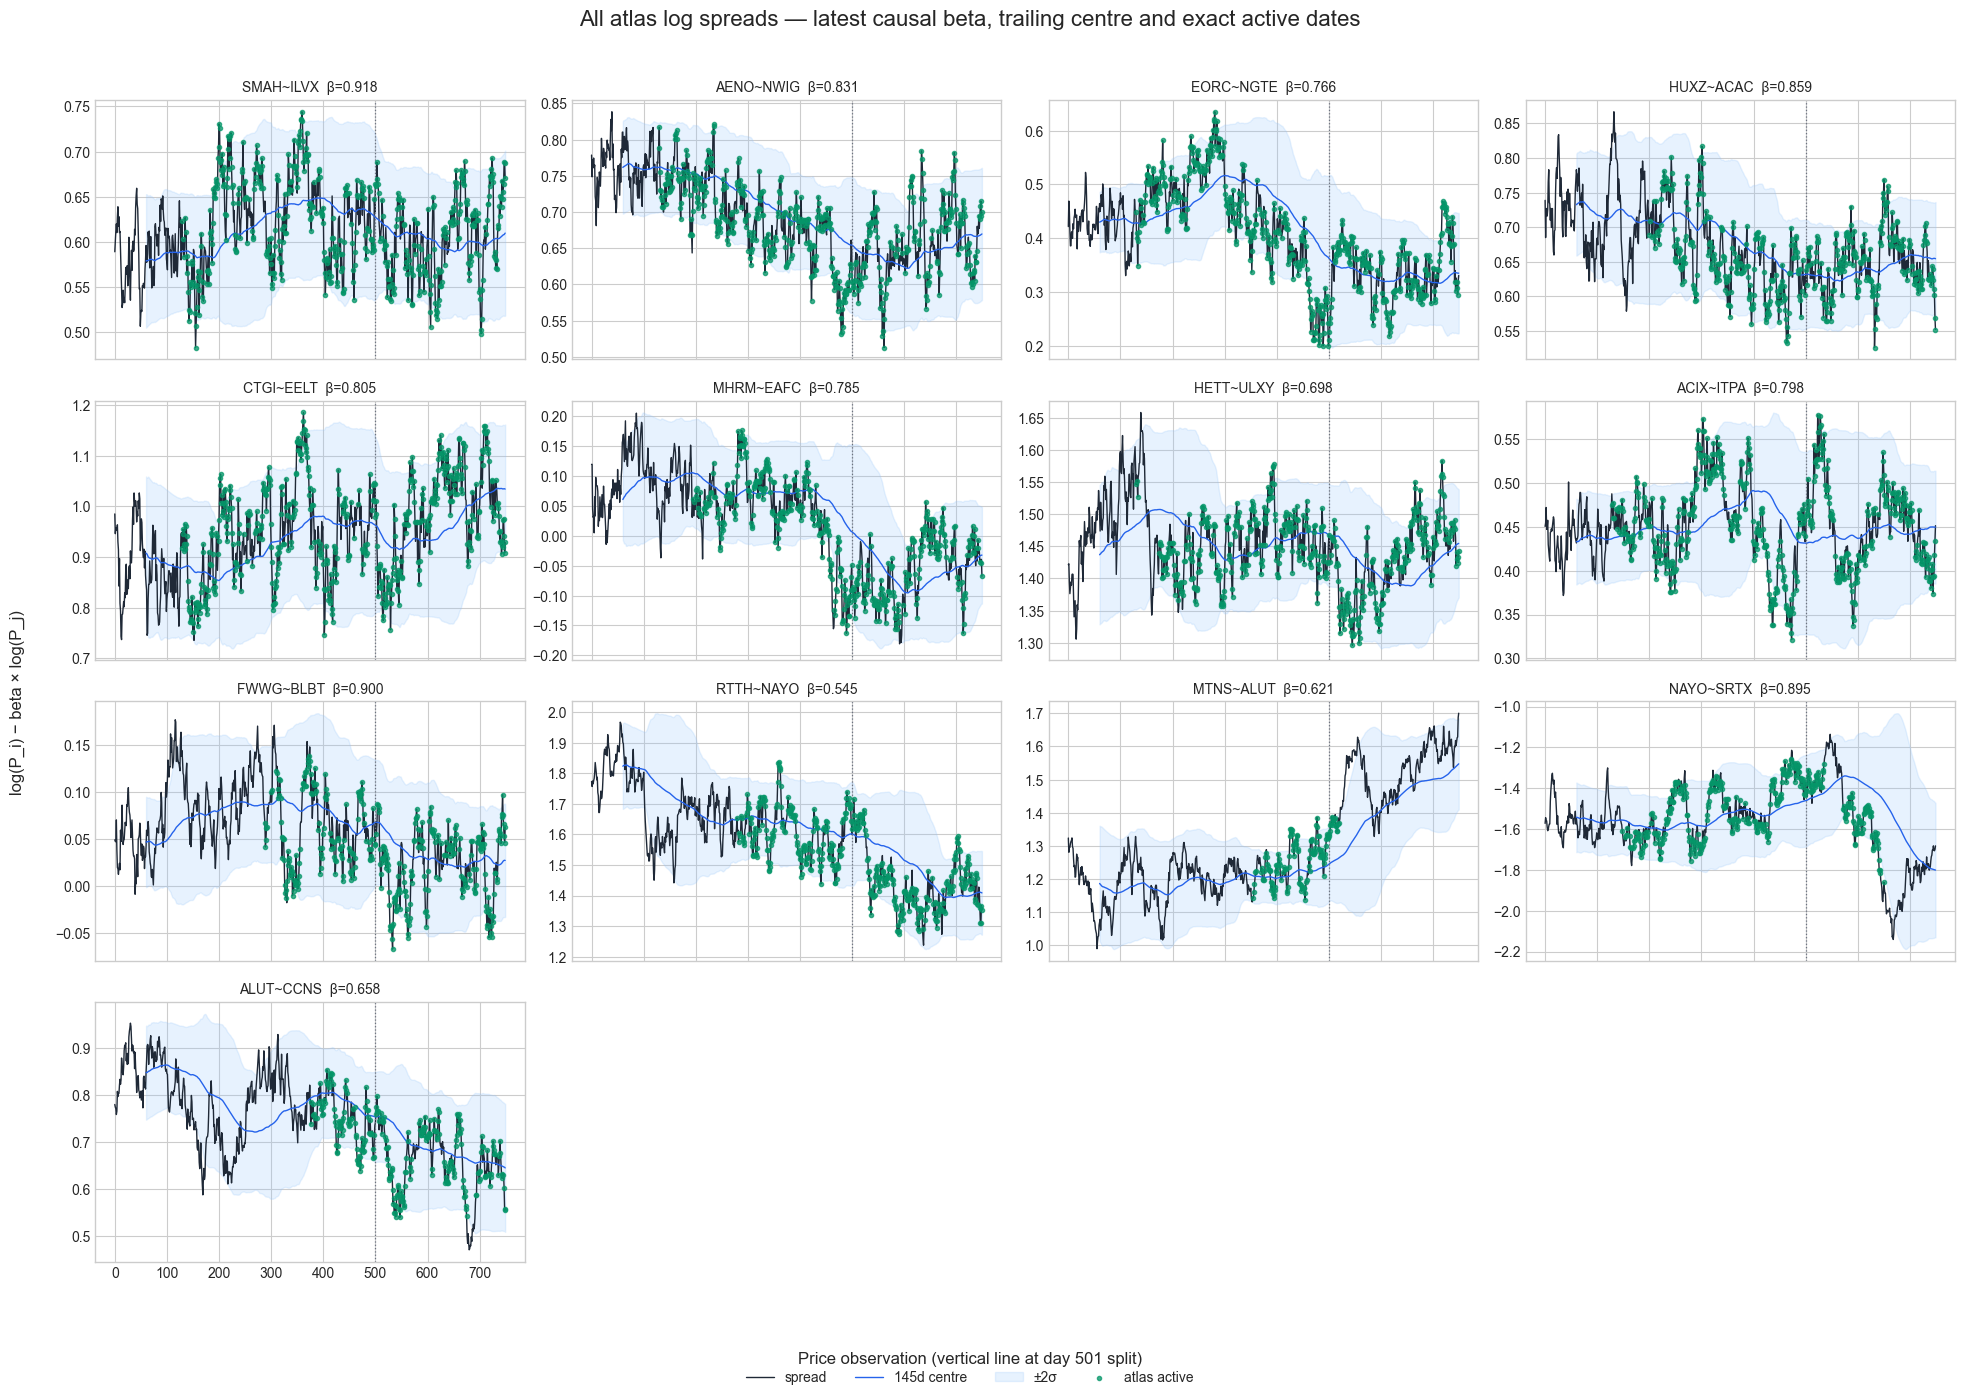

In [15]:

fig, axes = plt.subplots(4, 4, figsize=(20, 14), sharex=True)
axes = axes.ravel()

for ax, (i, j) in zip(axes, atlas_pairs):
    label = f"{names[i]}~{names[j]}"
    beta = float(relationship.loc[relationship.pair == label, "current_kalman_beta"].iloc[0])
    spread = pd.Series(log_prices[i] - beta * log_prices[j])
    centre = spread.rolling(Z_WINDOW, min_periods=60).mean().shift(1)
    width = spread.rolling(Z_WINDOW, min_periods=60).std(ddof=0).shift(1)
    h = causal[label]
    active_days = h.loc[h.active, "day"].to_numpy(int)

    ax.plot(spread.index, spread, color="#1f2937", lw=1.0, label="spread")
    ax.plot(centre.index, centre, color="#2563eb", lw=1.0, label="145d centre")
    ax.fill_between(spread.index, centre - 2 * width, centre + 2 * width,
                    color="#93c5fd", alpha=0.22, label="±2σ")
    if len(active_days):
        ax.scatter(active_days, spread.iloc[active_days], s=9, color="#059669",
                   alpha=0.75, label="atlas active", zorder=3)
    ax.set_title(f"{label}  β={beta:.3f}", fontsize=10)
    ax.axvline(500, color="#6b7280", ls=":", lw=0.9)

for ax in axes[len(atlas_pairs):]:
    ax.axis("off")

handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", bbox_to_anchor=(0.5, 0.004),
           ncol=4, frameon=False)
fig.suptitle("All atlas log spreads — latest causal beta, trailing centre and exact active dates", fontsize=16, y=0.995)
fig.supxlabel("Price observation (vertical line at day 501 split)", y=0.026)
fig.supylabel("log(P_i) − beta × log(P_j)")
fig.tight_layout(rect=[0.02, 0.055, 1, 0.98])
fig.savefig(OUT_DIR / "all_atlas_spreads_overview.png", dpi=160, bbox_inches="tight")
plt.show()



## Pair-by-pair diagnostics

For each pair:

1. normalized prices show broad co-movement;
2. the fixed-latest-beta spread shows equilibrium levels and exact active dates;
3. the causal Kalman beta path reveals hedge-ratio drift;
4. the exact causal z-score shows entry direction, dead zone, and break boundary.

The transposed table above each figure contains every relationship, gate, position, and standalone attribution field for that pair.


### 1. SMAH~ILVX (assets 10 and 46)

,value
i,10
j,46
current_kalman_beta,0.917643
full_OLS_alpha,0.192315
full_OLS_beta,1.030927
full_OLS_R2,0.947115
half_beta_change_pct,-12.121902
return_correlation,0.294665
EG_p_i_on_j,0.0
EG_p_j_on_i,0.0


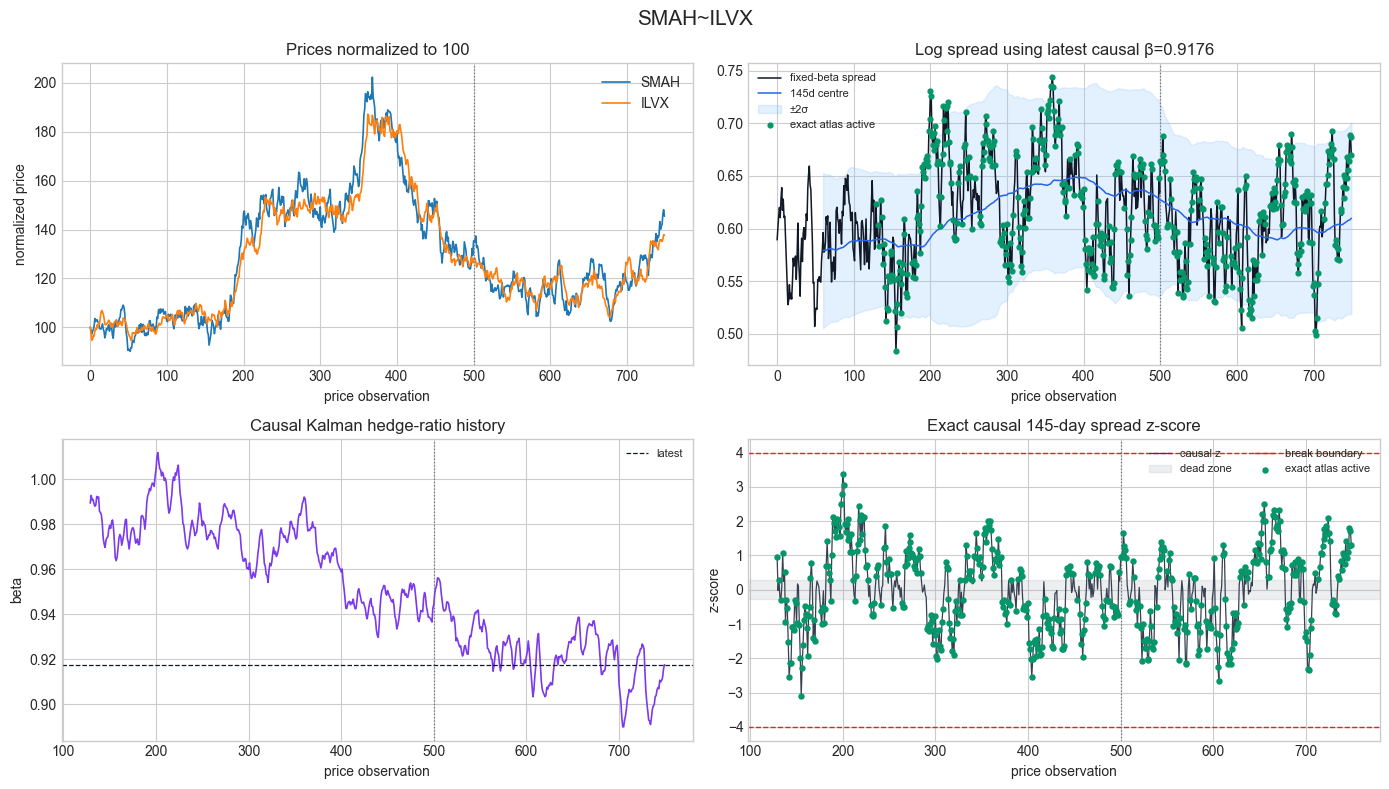

### 2. AENO~NWIG (assets 1 and 20)

,value
i,1
j,20
current_kalman_beta,0.830929
full_OLS_alpha,0.047514
full_OLS_beta,0.974878
full_OLS_R2,0.973362
half_beta_change_pct,-9.924842
return_correlation,0.258583
EG_p_i_on_j,0.0
EG_p_j_on_i,0.0


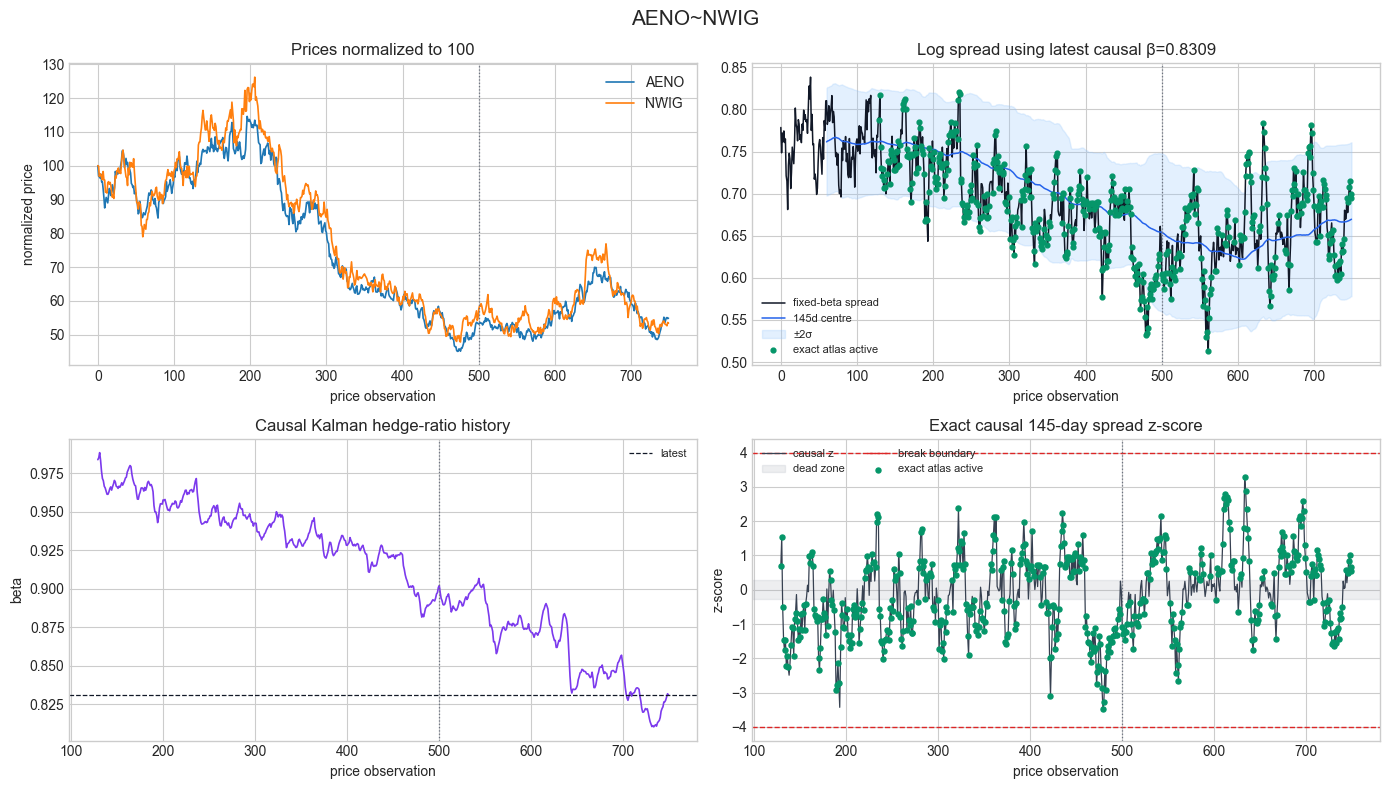

### 3. EORC~NGTE (assets 13 and 45)

,value
i,13
j,45
current_kalman_beta,0.765511
full_OLS_alpha,-0.352218
full_OLS_beta,0.962241
full_OLS_R2,0.97266
half_beta_change_pct,-3.125664
return_correlation,0.228164
EG_p_i_on_j,0.0
EG_p_j_on_i,0.0


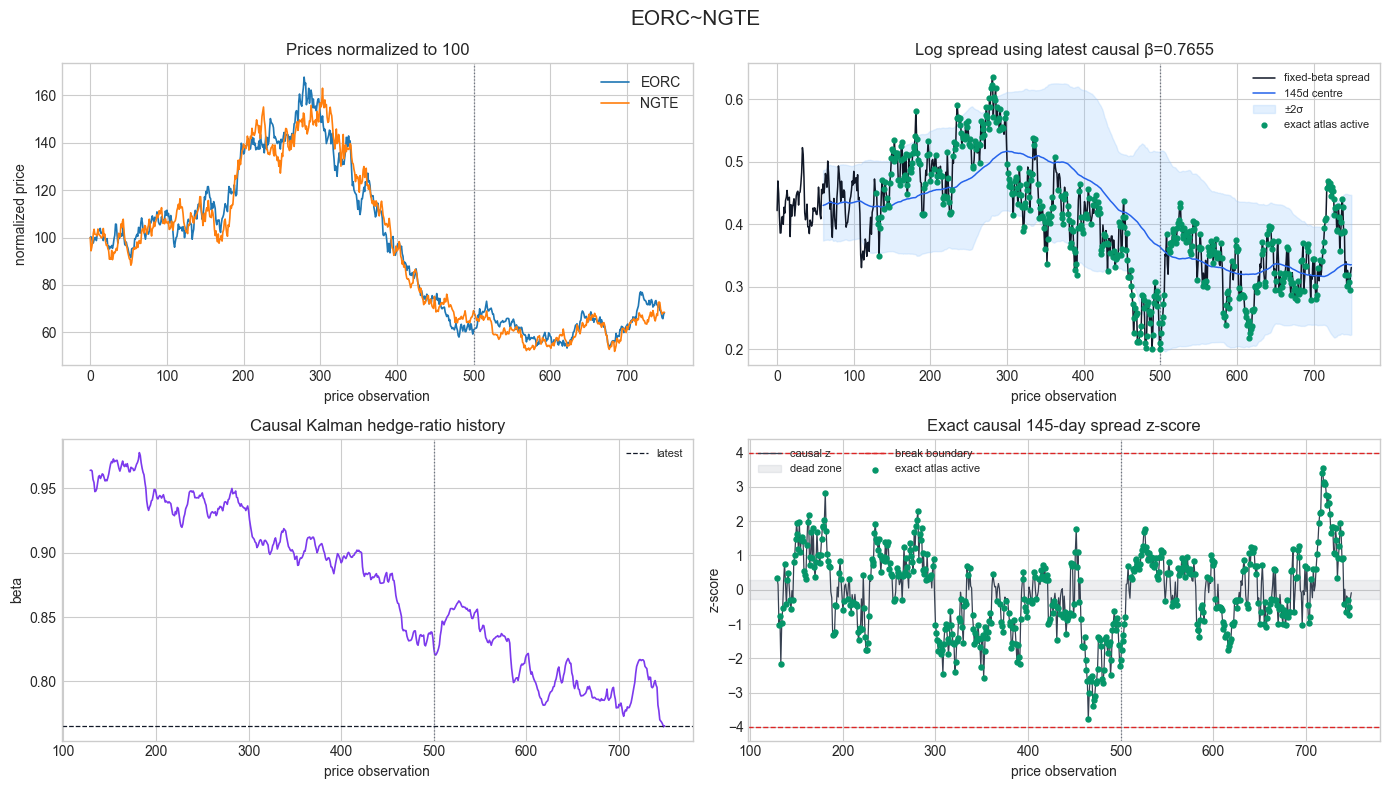

### 4. HUXZ~ACAC (assets 8 and 27)

,value
i,8
j,27
current_kalman_beta,0.858793
full_OLS_alpha,0.121141
full_OLS_beta,0.995731
full_OLS_R2,0.954662
half_beta_change_pct,-6.870914
return_correlation,0.303396
EG_p_i_on_j,0.0
EG_p_j_on_i,0.0


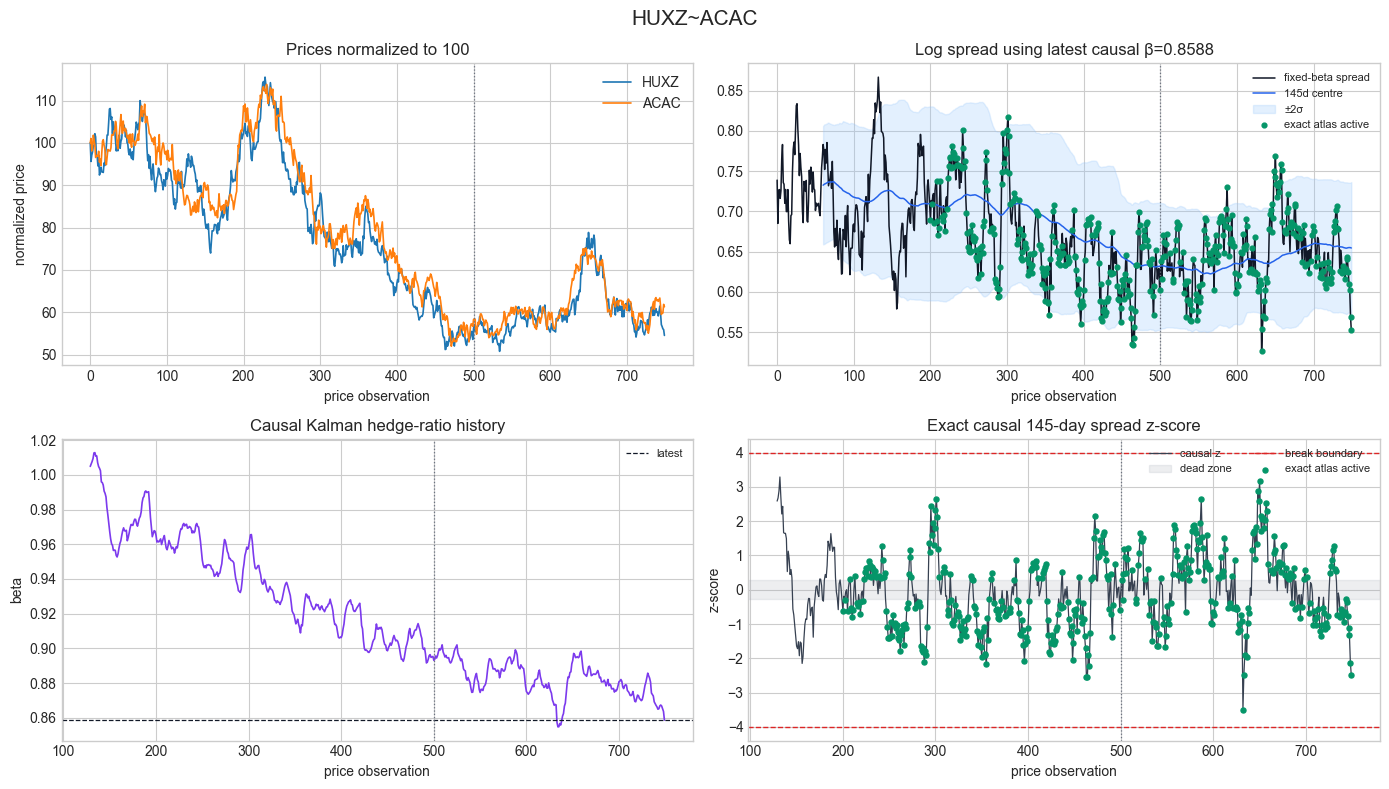

### 5. CTGI~EELT (assets 25 and 37)

,value
i,25
j,37
current_kalman_beta,0.805167
full_OLS_alpha,0.354965
full_OLS_beta,0.93288
full_OLS_R2,0.622398
half_beta_change_pct,-4.944205
return_correlation,0.225541
EG_p_i_on_j,0.000007
EG_p_j_on_i,0.0


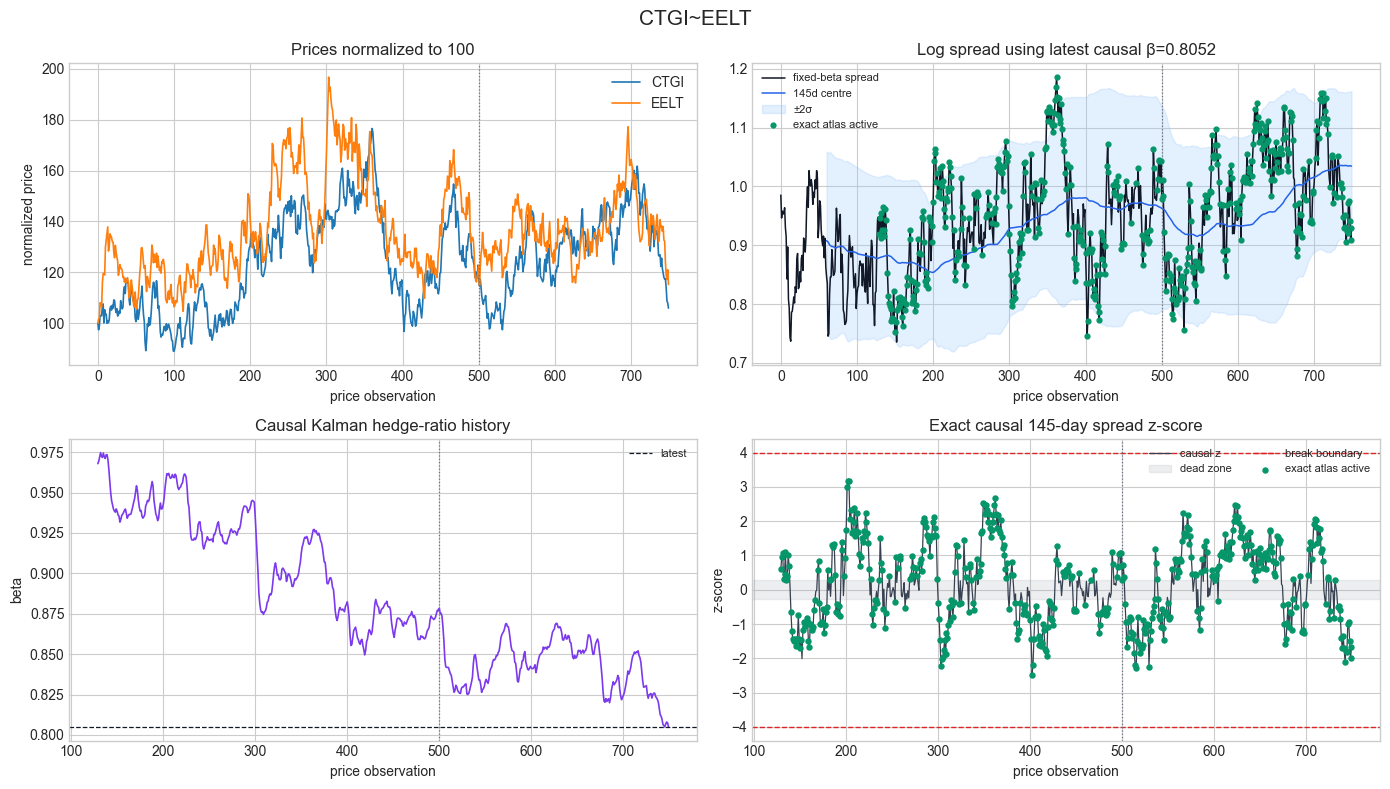

### 6. MHRM~EAFC (assets 49 and 50)

,value
i,49
j,50
current_kalman_beta,0.785096
full_OLS_alpha,-0.644231
full_OLS_beta,0.986844
full_OLS_R2,0.971228
half_beta_change_pct,40.576333
return_correlation,0.391064
EG_p_i_on_j,0.000001
EG_p_j_on_i,0.000001


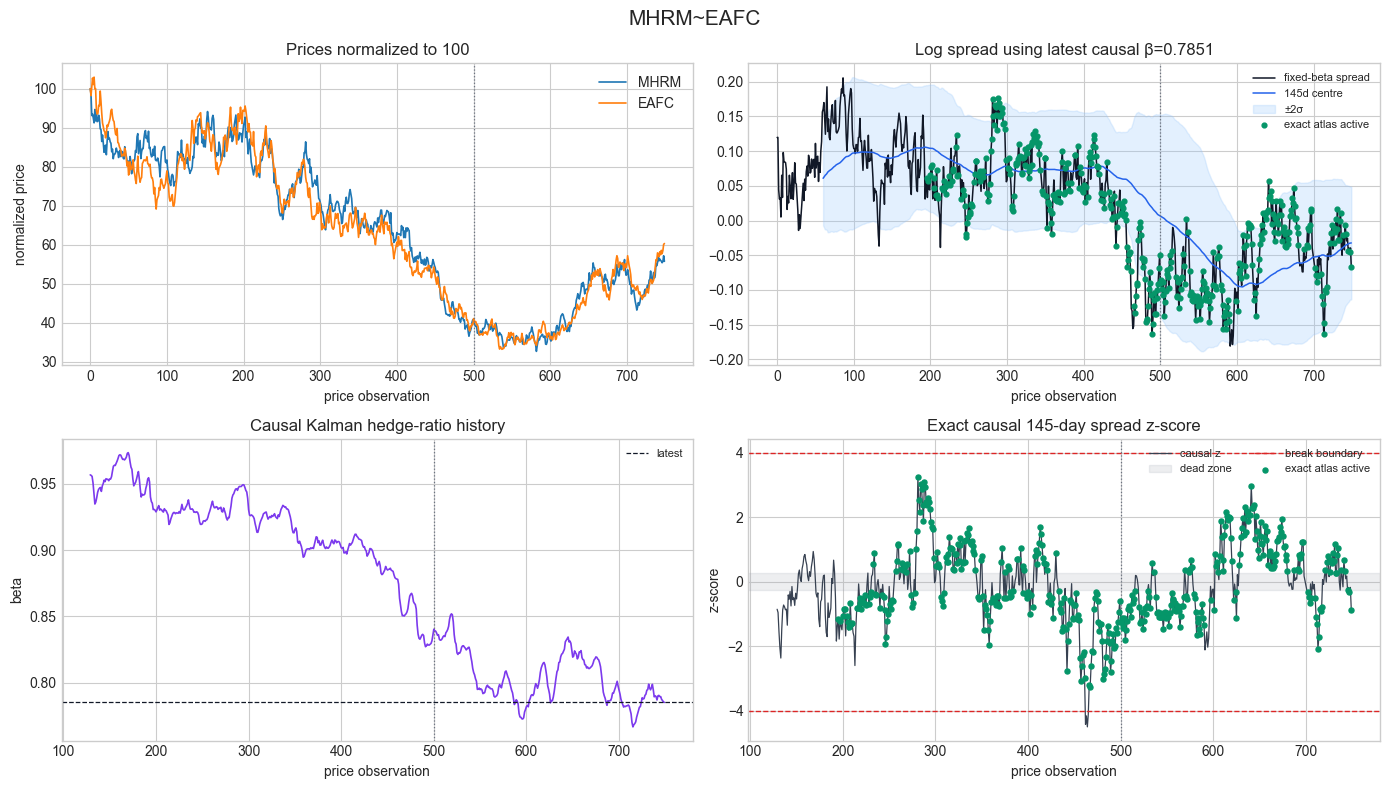

### 7. HETT~ULXY (assets 7 and 40)

,value
i,7
j,40
current_kalman_beta,0.697752
full_OLS_alpha,0.954415
full_OLS_beta,0.82624
full_OLS_R2,0.75544
half_beta_change_pct,28.88399
return_correlation,0.160253
EG_p_i_on_j,0.000001
EG_p_j_on_i,0.0


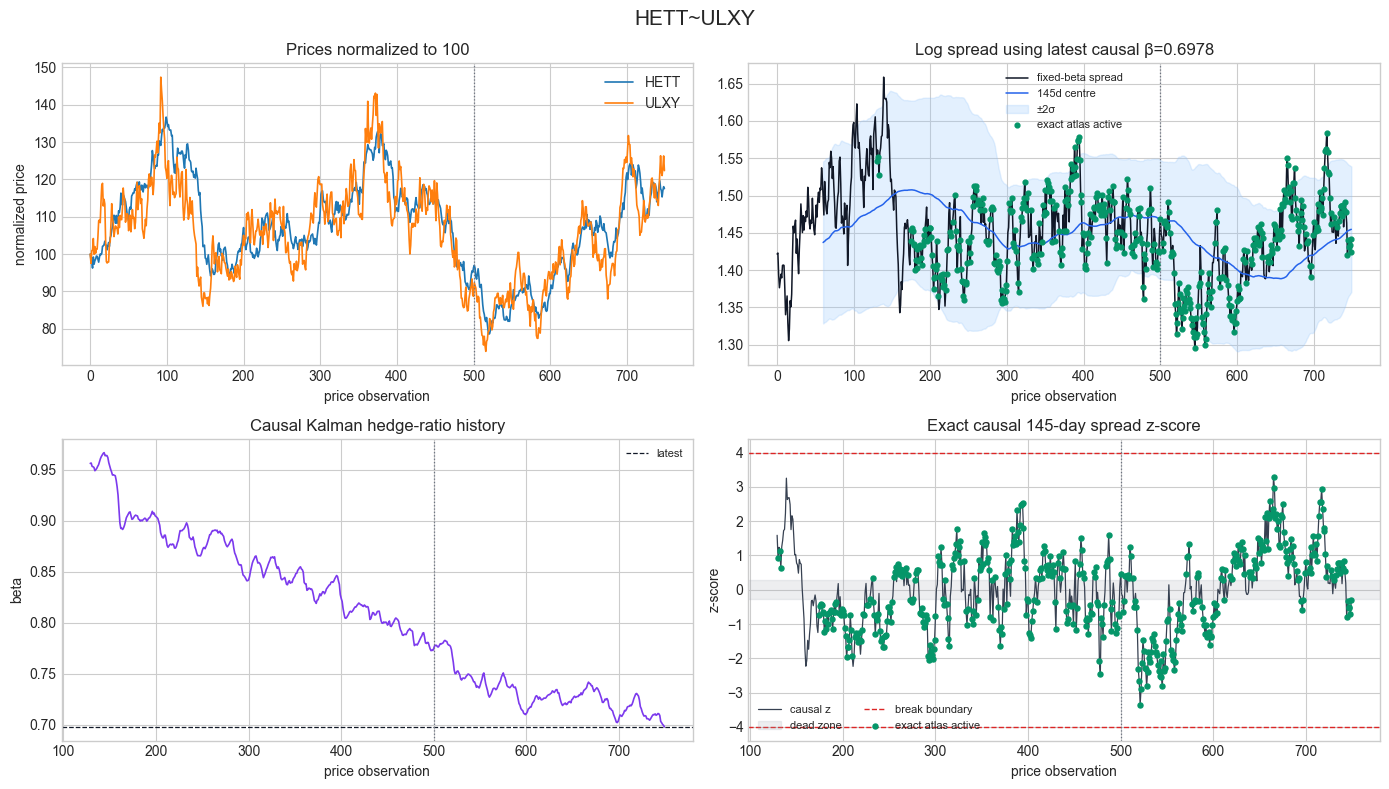

### 8. ACIX~ITPA (assets 31 and 43)

,value
i,31
j,43
current_kalman_beta,0.798216
full_OLS_alpha,0.045501
full_OLS_beta,0.926363
full_OLS_R2,0.803507
half_beta_change_pct,-10.405786
return_correlation,0.435801
EG_p_i_on_j,0.00007
EG_p_j_on_i,0.000042


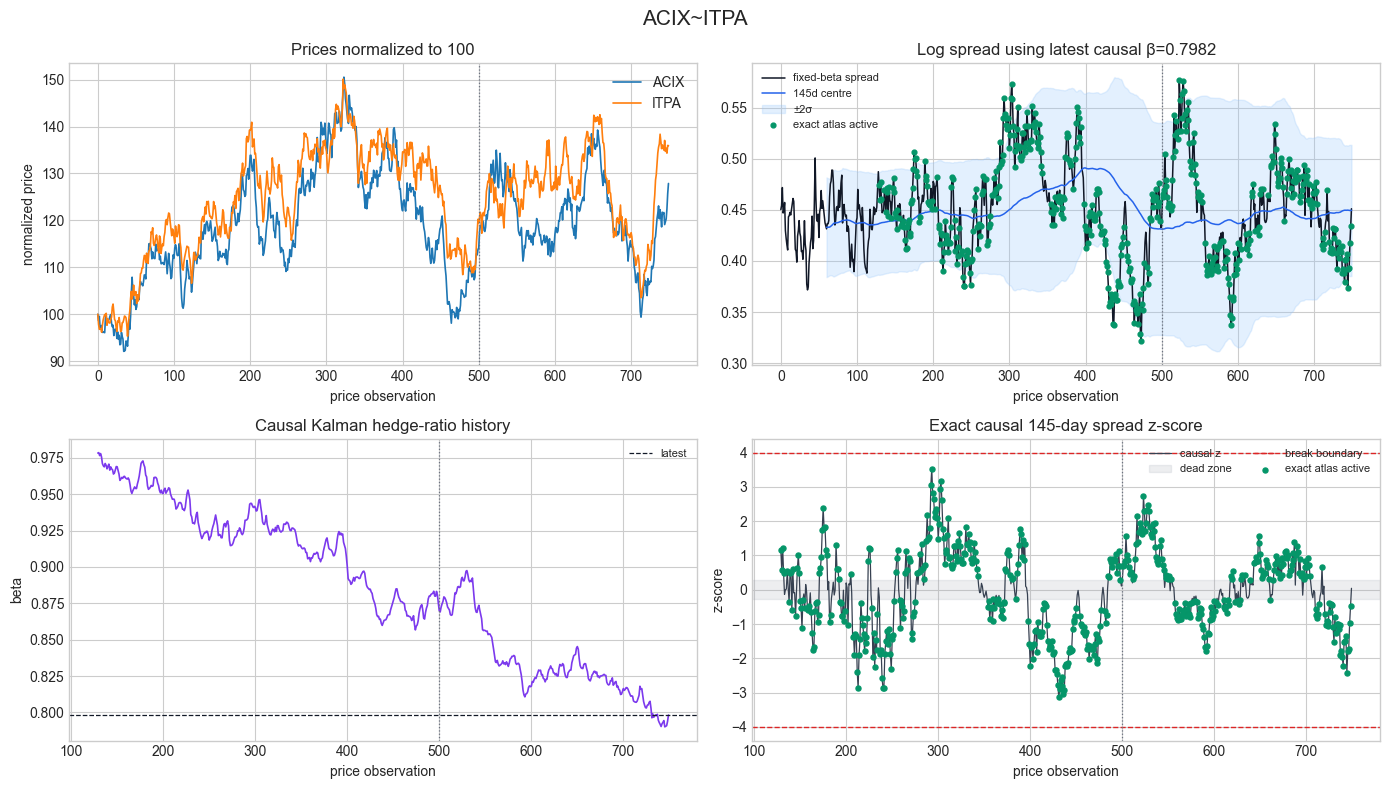

### 9. FWWG~BLBT (assets 36 and 41)

,value
i,36
j,41
current_kalman_beta,0.90016
full_OLS_alpha,-0.311686
full_OLS_beta,1.001332
full_OLS_R2,0.961356
half_beta_change_pct,30.653132
return_correlation,0.379899
EG_p_i_on_j,0.000031
EG_p_j_on_i,0.000036


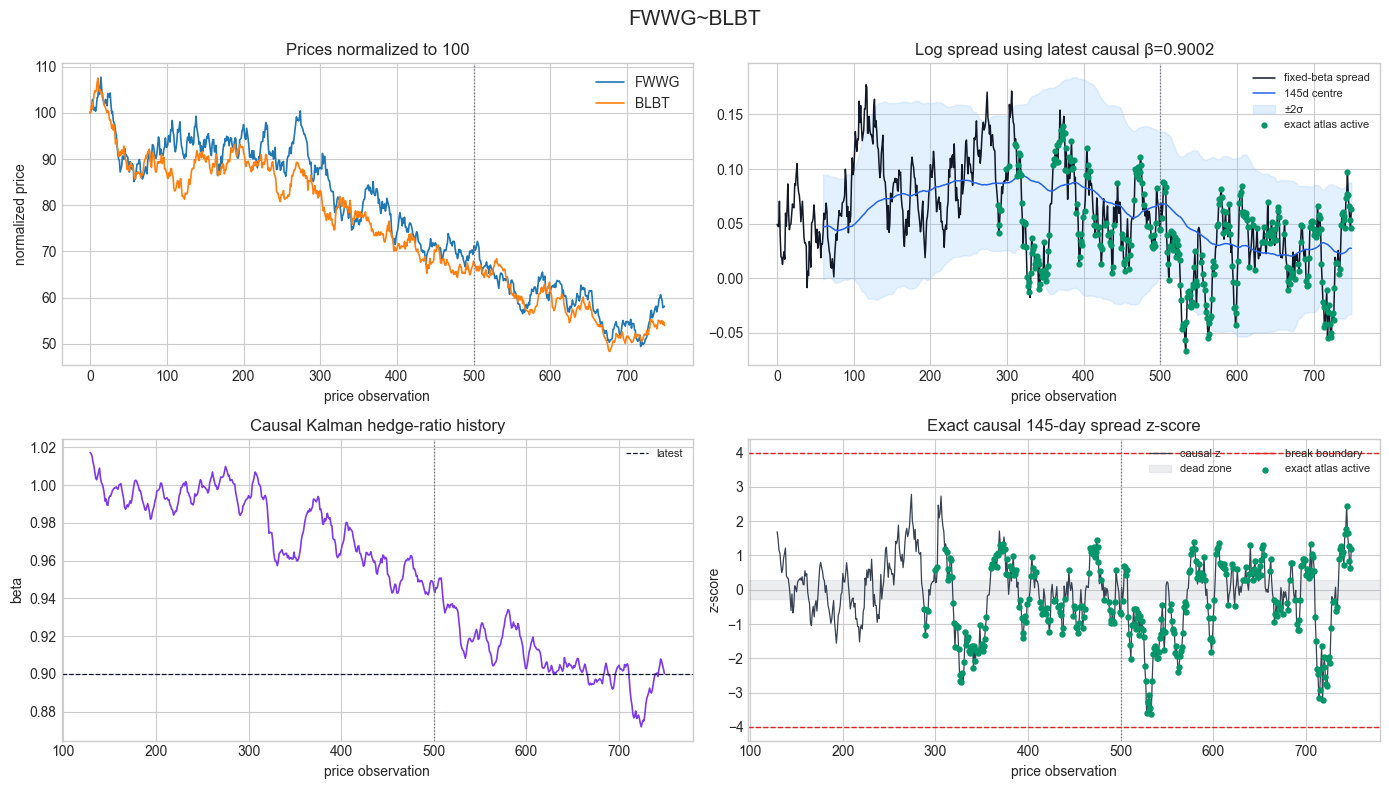

### 10. RTTH~NAYO (assets 18 and 35)

,value
i,18
j,35
current_kalman_beta,0.545069
full_OLS_alpha,0.185336
full_OLS_beta,0.964283
full_OLS_R2,0.861918
half_beta_change_pct,25.34993
return_correlation,0.210559
EG_p_i_on_j,0.000012
EG_p_j_on_i,0.000011


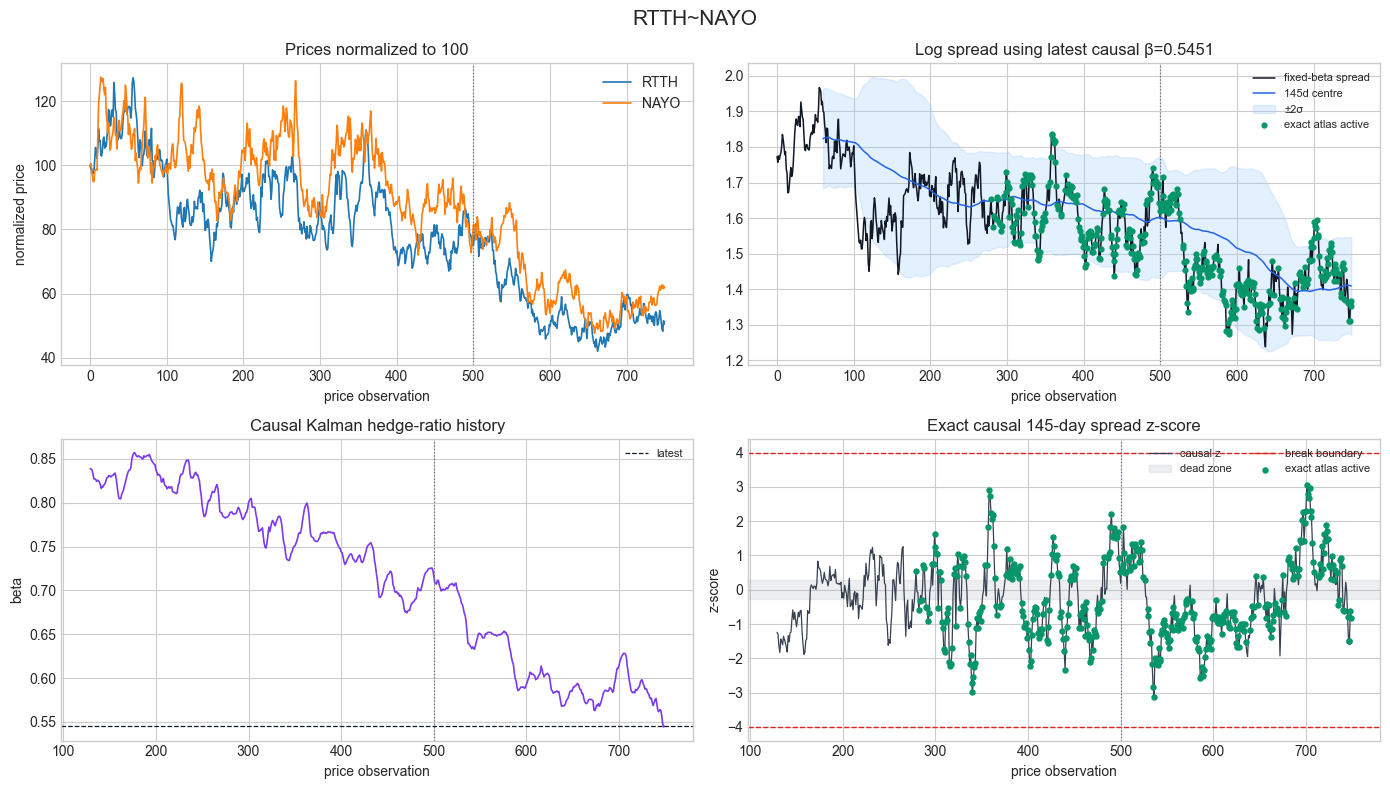

### 11. MTNS~ALUT (assets 33 and 26)

,value
i,33
j,26
current_kalman_beta,0.621328
full_OLS_alpha,2.880552
full_OLS_beta,0.022763
full_OLS_R2,0.00552
half_beta_change_pct,-121.051491
return_correlation,0.136748
EG_p_i_on_j,0.050366
EG_p_j_on_i,0.924451


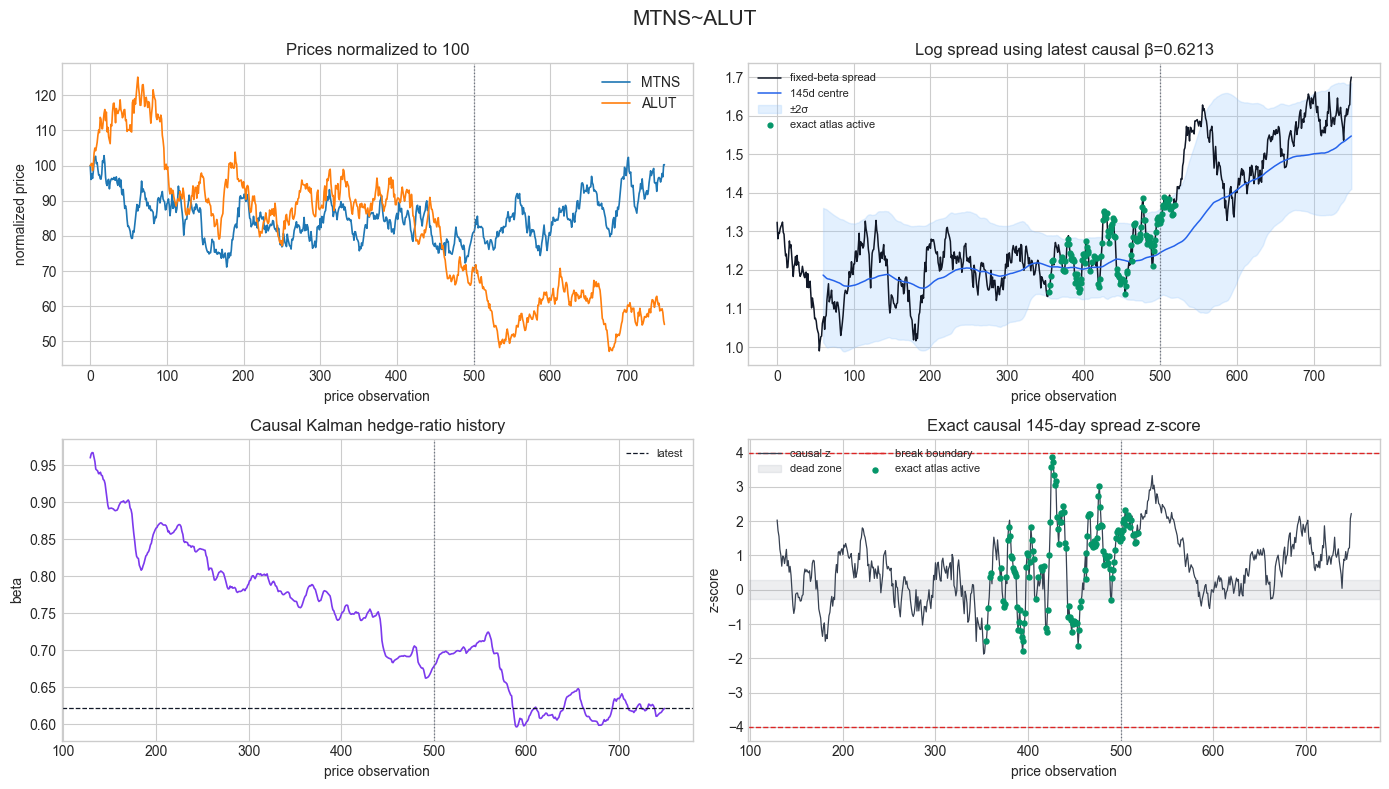

### 12. NAYO~SRTX (assets 35 and 28)

,value
i,35
j,28
current_kalman_beta,0.895367
full_OLS_alpha,-0.752458
full_OLS_beta,0.747674
full_OLS_R2,0.520765
half_beta_change_pct,-11.23244
return_correlation,0.162332
EG_p_i_on_j,0.24155
EG_p_j_on_i,0.351606


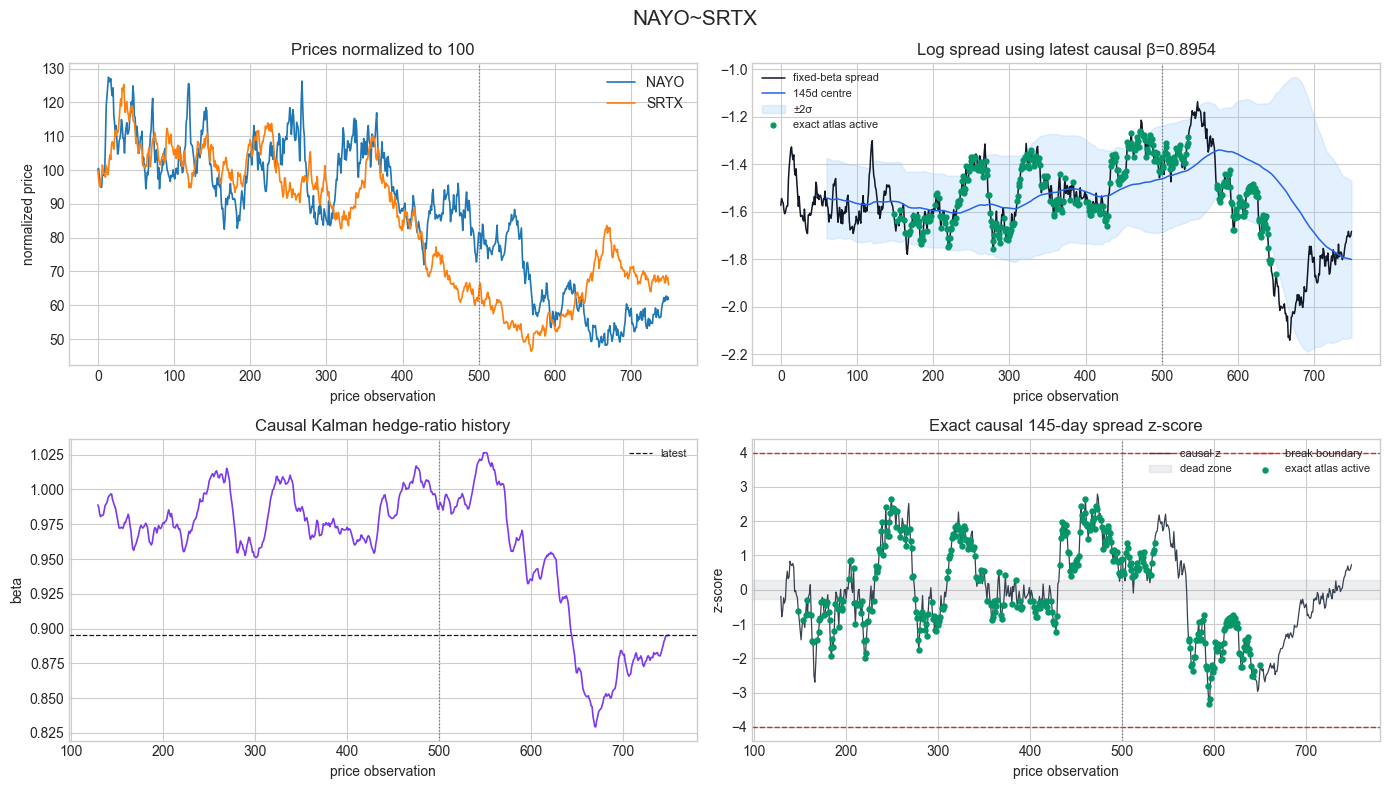

### 13. ALUT~CCNS (assets 26 and 32)

,value
i,26
j,32
current_kalman_beta,0.658254
full_OLS_alpha,0.090394
full_OLS_beta,0.884524
full_OLS_R2,0.911879
half_beta_change_pct,35.504956
return_correlation,0.267708
EG_p_i_on_j,0.000933
EG_p_j_on_i,0.000773


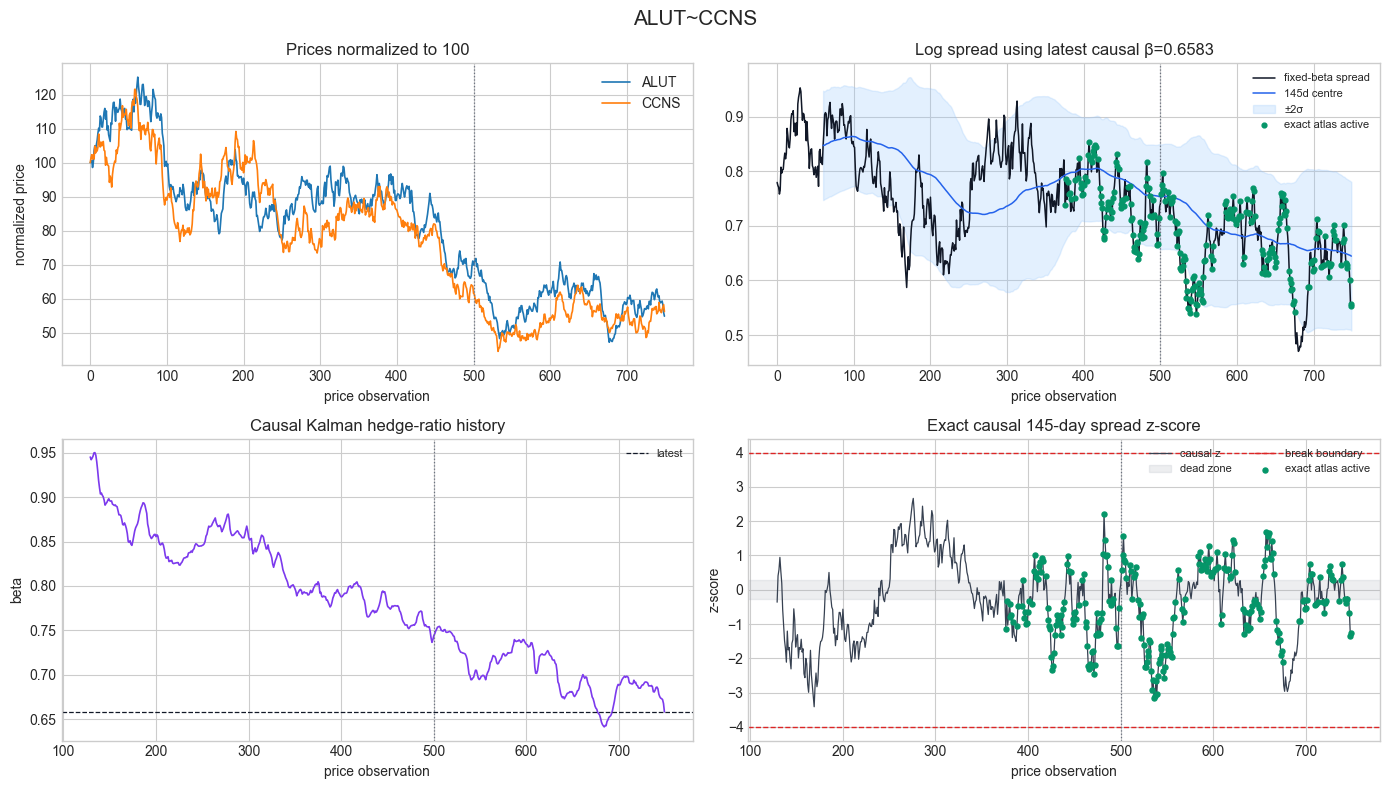

In [9]:

for pair_number, (i, j) in enumerate(atlas_pairs, start=1):
    label = f"{names[i]}~{names[j]}"
    display(Markdown(f"### {pair_number}. {label} (assets {i} and {j})"))
    pair_row = summary.loc[summary.pair == label].set_index("pair").T
    pair_row.columns = ["value"]
    display(pair_row.round(5))

    h = causal[label]
    beta = float(pair_row.loc["current_kalman_beta", "value"])
    fixed_spread = pd.Series(log_prices[i] - beta * log_prices[j])
    centre = fixed_spread.rolling(Z_WINDOW, min_periods=60).mean().shift(1)
    width = fixed_spread.rolling(Z_WINDOW, min_periods=60).std(ddof=0).shift(1)
    active_days = h.loc[h.active, "day"].to_numpy(int)

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))

    axes[0, 0].plot(100 * prices[i] / prices[i, 0], label=names[i], lw=1.2)
    axes[0, 0].plot(100 * prices[j] / prices[j, 0], label=names[j], lw=1.2)
    axes[0, 0].set_title("Prices normalized to 100")
    axes[0, 0].set_ylabel("normalized price")
    axes[0, 0].legend()

    axes[0, 1].plot(fixed_spread, color="#111827", lw=1.1, label="fixed-beta spread")
    axes[0, 1].plot(centre, color="#2563eb", lw=1.1, label="145d centre")
    axes[0, 1].fill_between(fixed_spread.index, centre - 2 * width, centre + 2 * width,
                            color="#93c5fd", alpha=0.25, label="±2σ")
    if len(active_days):
        axes[0, 1].scatter(active_days, fixed_spread.iloc[active_days], s=12,
                           color="#059669", label="exact atlas active", zorder=3)
    axes[0, 1].set_title(f"Log spread using latest causal β={beta:.4f}")
    axes[0, 1].legend(fontsize=8)

    axes[1, 0].plot(h.day, h.beta, color="#7c3aed", lw=1.2)
    axes[1, 0].axhline(beta, color="#111827", ls="--", lw=0.9, label="latest")
    axes[1, 0].set_title("Causal Kalman hedge-ratio history")
    axes[1, 0].set_ylabel("beta")
    axes[1, 0].legend(fontsize=8)

    axes[1, 1].plot(h.day, h.z, color="#374151", lw=0.9, label="causal z")
    axes[1, 1].axhspan(-Z_DEAD, Z_DEAD, color="#9ca3af", alpha=0.18, label="dead zone")
    axes[1, 1].axhline(Z_MAX, color="#dc2626", ls="--", lw=1.0)
    axes[1, 1].axhline(-Z_MAX, color="#dc2626", ls="--", lw=1.0, label="break boundary")
    if len(active_days):
        active_rows = h[h.active]
        axes[1, 1].scatter(active_rows.day, active_rows.z, s=13,
                           color="#059669", label="exact atlas active", zorder=3)
    axes[1, 1].set_title("Exact causal 145-day spread z-score")
    axes[1, 1].set_ylabel("z-score")
    axes[1, 1].legend(fontsize=8, ncol=2)

    for ax in axes.ravel():
        ax.axvline(500, color="#6b7280", ls=":", lw=0.9)
        ax.set_xlabel("price observation")

    fig.suptitle(label, fontsize=15)
    fig.tight_layout()
    safe_label = label.replace("~", "_")
    fig.savefig(OUT_DIR / f"{pair_number:02d}_{safe_label}_diagnostics.png",
                dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)



## How to use these diagnostics

- A low Engle–Granger p-value or ADF statistic supports historical relationship health; it does **not** specify direction or guarantee future profit.
- The signed causal z-score provides direction. Positive z means short the first asset and buy the second.
- A drifting causal beta or large half-sample beta change warns that a fixed relationship is unstable even if the full-sample test is significant.
- Positive kappa and a finite, short half-life support faster mean reversion. They remain estimates, not proofs.
- Residual market beta near zero indicates that the OLS-style fixed-beta spread has low broad-market return exposure. The atlas itself uses equal-dollar legs, so this statistic is diagnostic rather than an exact neutrality guarantee.
- Standalone after-cost PnL is the most strategy-relevant historical check, but it still shares the supplied data with pair selection. Treat it as evidence, not an unbiased estimate of future OOS profitability.
- The exact `currently_active` flag is pair-local. In the integrated portfolio, shared legs, ridge agreement, dollar clipping, and integer shares can alter realized exposure.
